In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

In [10]:
from pathlib import Path

dataset_path = Path("/content/tomato_30_percent")

print(dataset_path.exists())

True


In [11]:
import tensorflow as tf

train_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.30,
    subset="training",
    seed=42,
    image_size=(160, 160),
    batch_size=32,
    label_mode="int"
)

temp_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.30,
    subset="validation",
    seed=42,
    image_size=(160, 160),
    batch_size=32,
    label_mode="int"
)

class_names = train_dataset.class_names
num_classes = len(class_names)

val_batches = tf.data.experimental.cardinality(temp_dataset)

validation_dataset = temp_dataset.take(val_batches // 2)
test_dataset = temp_dataset.skip(val_batches // 2)

AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(AUTOTUNE)
validation_dataset = validation_dataset.prefetch(AUTOTUNE)
test_dataset = test_dataset.prefetch(AUTOTUNE)

Found 4799 files belonging to 10 classes.
Using 3360 files for training.
Found 4799 files belonging to 10 classes.
Using 1439 files for validation.


In [12]:
print("Classes:", num_classes)
print("Class names:", class_names)

Classes: 10
Class names: ['Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']


In [13]:
print("Model output classes:", model.output_shape[-1])
print("Dataset classes:", num_classes)

print("Training batches:",
      tf.data.experimental.cardinality(train_dataset).numpy())

print("Validation batches:",
      tf.data.experimental.cardinality(validation_dataset).numpy())

print("Test batches:",
      tf.data.experimental.cardinality(test_dataset).numpy())

Model output classes: 10
Dataset classes: 10
Training batches: 105
Validation batches: 22
Test batches: 23


In [14]:
fine_tune_history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=5,
    callbacks=[
        early_stop,
        reduce_lr
    ]
)

Epoch 1/5
105/105 ━━━━━━━━━━━━━━━━━━━━ 43s 360ms/step - accuracy: 0.9396 - loss: 0.1783 - val_accuracy: 0.8778 - val_loss: 0.3282 - learning_rate: 1.0000e-05
Epoch 2/5
105/105 ━━━━━━━━━━━━━━━━━━━━ 37s 357ms/step - accuracy: 0.9426 - loss: 0.1706 - val_accuracy: 0.9062 - val_loss: 0.2854 - learning_rate: 1.0000e-05
Epoch 3/5
105/105 ━━━━━━━━━━━━━━━━━━━━ 37s 355ms/step - accuracy: 0.9482 - loss: 0.1506 - val_accuracy: 0.8778 - val_loss: 0.3609 - learning_rate: 1.0000e-05
Epoch 4/5
105/105 ━━━━━━━━━━━━━━━━━━━━ 37s 356ms/step - accuracy: 0.9533 - loss: 0.1336 - val_accuracy: 0.8693 - val_loss: 0.3456 - learning_rate: 1.0000e-05
Epoch 5/5
105/105 ━━━━━━━━━━━━━━━━━━━━ 38s 360ms/step - accuracy: 0.9616 - loss: 0.1146 - val_accuracy: 0.8977 - val_loss: 0.2805 - learning_rate: 2.0000e-06


In [15]:
print("Training Accuracy:",
      fine_tune_history.history["accuracy"][-1])

print("Validation Accuracy:",
      fine_tune_history.history["val_accuracy"][-1])

Training Accuracy: 0.9616071581840515
Validation Accuracy: 0.8977272510528564


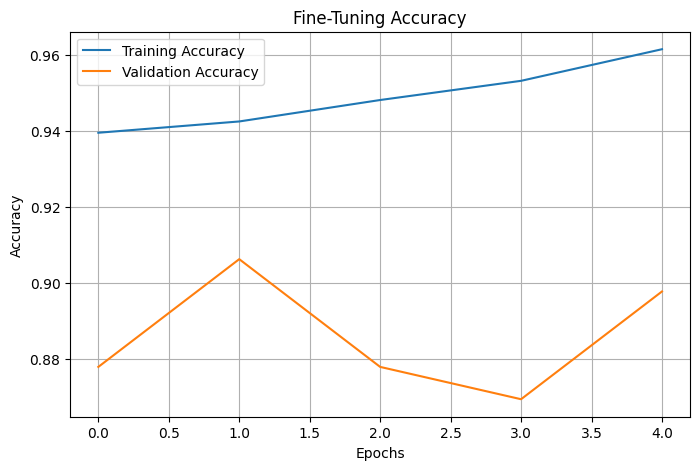

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(
    fine_tune_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    fine_tune_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Fine-Tuning Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

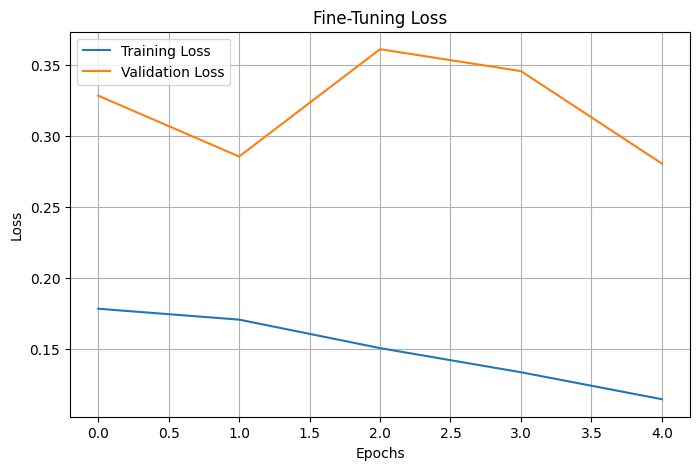

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(
    fine_tune_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    fine_tune_history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Fine-Tuning Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

In [18]:
test_loss, test_accuracy = model.evaluate(test_dataset)

print("Fine-Tuned Test Loss:", test_loss)
print("Fine-Tuned Test Accuracy:", test_accuracy)

23/23 ━━━━━━━━━━━━━━━━━━━━ 6s 246ms/step - accuracy: 0.8912 - loss: 0.3194
Fine-Tuned Test Loss: 0.3194122612476349
Fine-Tuned Test Accuracy: 0.8911564350128174


In [19]:
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Accuracy: 89.12%


In [20]:
y_true = []
y_pred = []

for images, labels in test_dataset:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

In [21]:
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
)

print(report)

                                             precision    recall  f1-score   support

                      Tomato_Bacterial_spot       0.82      0.99      0.89        86
                        Tomato_Early_blight       0.92      0.47      0.62        47
                         Tomato_Late_blight       0.95      0.86      0.90        80
                           Tomato_Leaf_Mold       0.86      0.91      0.88        46
                  Tomato_Septoria_leaf_spot       0.89      0.90      0.89        86
Tomato_Spider_mites_Two_spotted_spider_mite       0.91      0.85      0.88        80
                        Tomato__Target_Spot       0.75      0.90      0.82        81
      Tomato__Tomato_YellowLeaf__Curl_Virus       1.00      0.94      0.97       145
                Tomato__Tomato_mosaic_virus       0.92      0.92      0.92        13
                             Tomato_healthy       0.88      0.96      0.92        71

                                   accuracy                    

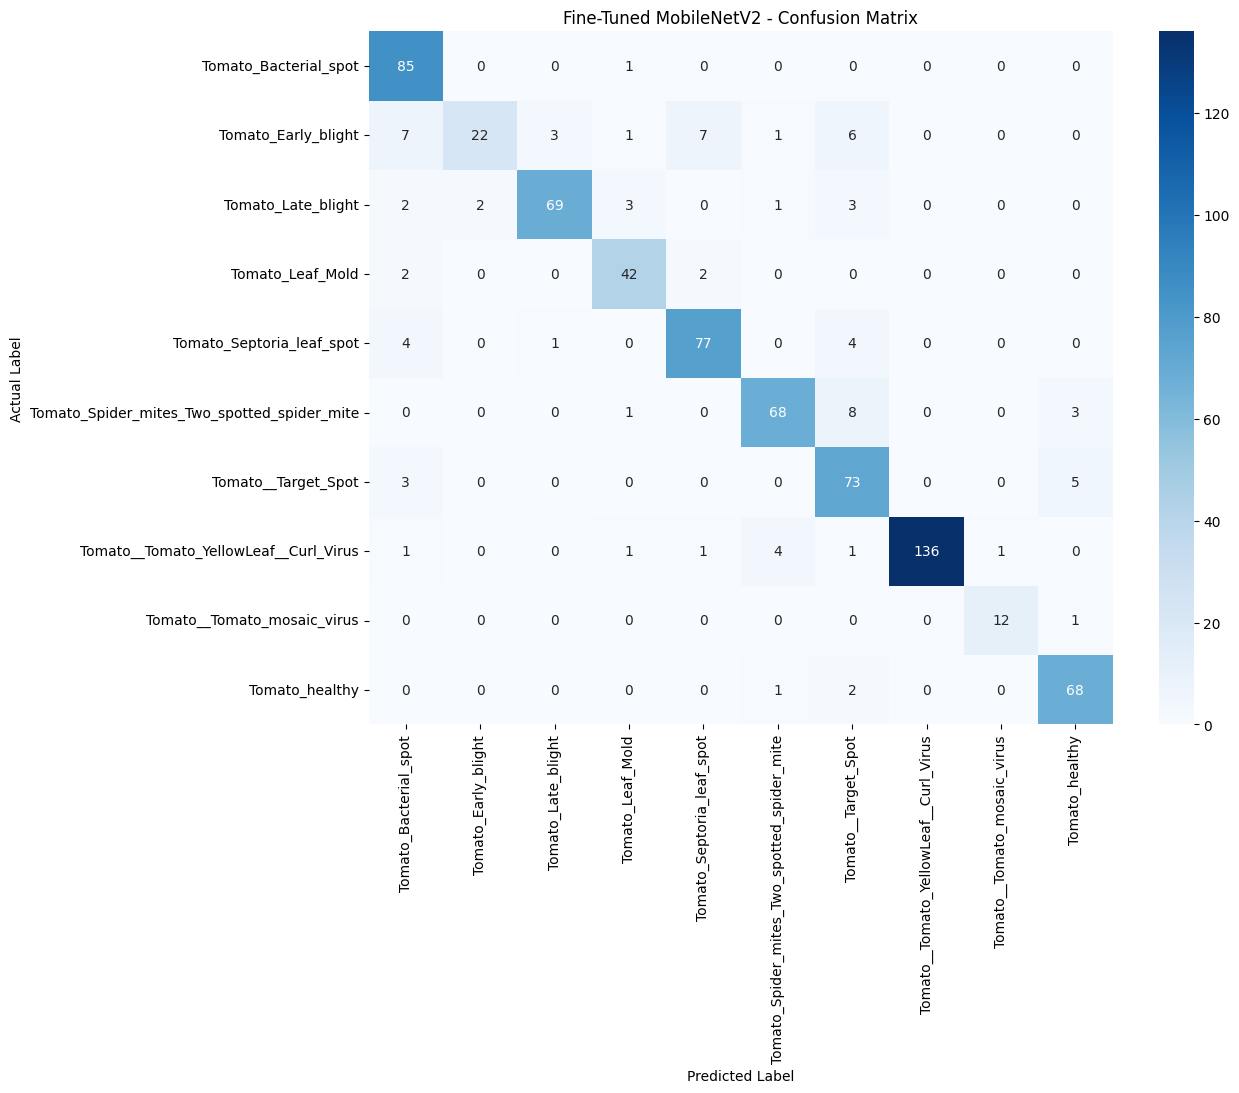

In [22]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Fine-Tuned MobileNetV2 - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.show()

In [23]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "Custom CNN",
        "MobileNetV2",
        "Fine-Tuned MobileNetV2"
    ],
    "Test Accuracy": [
        75.0,
        85.0,
        test_accuracy * 100
    ]
})

print(comparison)

                    Model  Test Accuracy
0              Custom CNN      75.000000
1             MobileNetV2      85.000000
2  Fine-Tuned MobileNetV2      89.115644


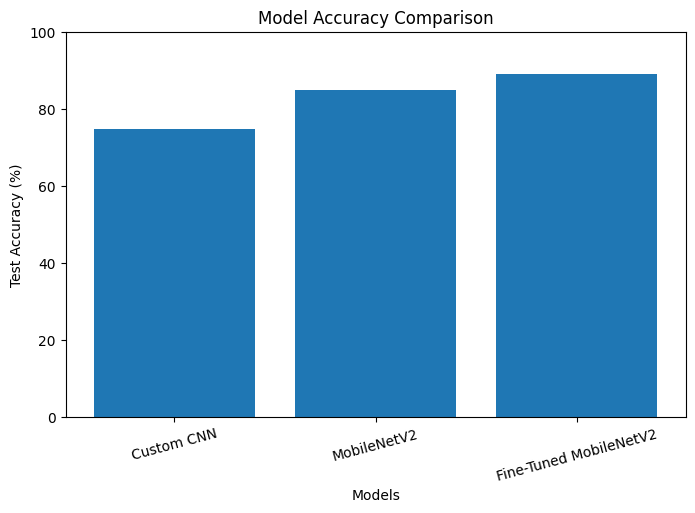

In [25]:
plt.figure(figsize=(8, 5))

plt.bar(
    comparison["Model"],
    comparison["Test Accuracy"]
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Models")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.show()

In [26]:
from pathlib import Path

model_dir = Path(
    "../models"
)

model_dir.mkdir(parents=True, exist_ok=True)

In [27]:
fine_tuned_model_path = model_dir / "tomato_disease_mobilenetv2_finetuned.keras"

model.save(fine_tuned_model_path)

print("Fine-tuned model saved successfully!")

Fine-tuned model saved successfully!


In [28]:
print("File exists:", fine_tuned_model_path.exists())
print("File size:", round(
    fine_tuned_model_path.stat().st_size / (1024 * 1024), 2
), "MB")

File exists: True
File size: 23.37 MB


In [29]:
model_path = Path(
    "../models/tomato_disease_mobilenetv2_finetuned.keras"
)

model = tf.keras.models.load_model(model_path)

print("Model loaded successfully!")

Model loaded successfully!
